# 02 · Can we reproduce the published accuracy?

**In one sentence:** we train three standard models on all the columns the dataset provides, and check whether we get the 99.9%+ accuracy that published papers report.

**Why start here:** before trying anything new, we check that our setup gives the same answer as everyone else. If it didn't, something in our data or code would be wrong.

| Published result | Accuracy |
|---|---|
| Prasad & Chandra 2024 (the dataset's own paper) | 99.79% |
| Bao et al. 2026, Random Forest | 99.99% |

### Words you need for this notebook
- **Model:** a program that learns from examples. It looks at many links whose answer we know (phishing or not) and learns rules to guess the answer for new links.
- **Columns (or features):** the numbers describing each link that the model looks at, e.g. its length or whether it uses HTTPS.
- **Train / validation / test:** we divide the links into three parts (notebook 01b). The model *learns* from train, we *choose settings* with validation, and we *score it once* on test. Test links are never seen before the final score.
- **Split by site owner:** all links from the same website go into the same part, so the model is never tested on a site it has already seen.

### What happens below
1. Load the cleaned data and pick the 50 numeric columns.
2. Train three models: Logistic Regression, Random Forest, XGBoost.
3. Compare their scores, and look at which columns they rely on.

Each model is trained and tested on **5 different splits** of the data, and we report the average. That way one lucky split can't fool us.

## Step 1 · Load the data

`load_clean()` is the same loading and cleaning code from notebook 01, so every notebook works on identical rows.

- `y` is the answer we want to predict: `is_phishing` (1 = phishing, 0 = legitimate).
- `X` is what the model may look at: every **numeric** column. The four text columns (the URL itself, domain, TLD, page title) are left out, because these models only accept numbers.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.experiment import run, summary_table
from phishguard.modeling import param_grid

df = load_clean()
y = df[TARGET]
X = df.drop(columns=TARGET).select_dtypes("number")
print(X.shape[1], "numeric columns (the 4 text columns URL, Domain, TLD, Title are left out)")

50 numeric columns (the 4 text columns URL, Domain, TLD, Title are left out)


**50 columns.** They come from three places (we sort them out properly in notebook 06):
- facts about the URL, e.g. `URLLength`, `IsHTTPS`;
- counts from the downloaded web page, e.g. `LineOfCode`, `NoOfImage`;
- `URLSimilarityIndex`, a score of how similar the link is to a list of known legitimate sites.

## Step 2 · Model 1: Logistic Regression

**The idea:** give every column a weight, add up *weight × value* for a link, and turn the total into a probability between 0 and 1. A large total means "probably phishing". Training means finding the weights that best separate the two classes. It's the simplest model here, which is why it's a good first check.

**The code, piece by piece:**
- `StandardScaler()` rescales every column to the same range (average 0, spread 1). Without it, a column counted in thousands (lines of code) would drown out a 0/1 column (uses HTTPS).
- `LogisticRegression(C=C)`: `C` controls how simple the weights must stay. A smaller `C` means simpler weights, which protects against learning noise.
- `param_grid(C=[0.01, 0.1, 1.0, 10.0])` lists the 4 values of `C` we try. Settings like `C` are called **hyperparameters**: we choose them; the model doesn't learn them.

**What `run(...)` does** (the same for every model in the project, `src/phishguard/experiment.py`), for each of the 5 splits:
1. trains one model per setting on *train* and keeps the setting that does best on *validation*;
2. picks the **threshold**, the probability above which we say "phishing", again on validation;
3. scores the *test* part once and saves the result in `results/m2/`.

`lambda C: ...` is just a short way to write "a function that builds a fresh model for a given `C`".

In [2]:
logreg = run(
    "LogReg (all columns)",
    lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)),
    param_grid(C=[0.01, 0.1, 1.0, 10.0]),
    X, y, df, features="all provided columns", group="m2",
)
logreg.per_seed[["seed", "accuracy", "fp", "fn"]]

,seed,accuracy,fp,fn
0,42,0.999915,2,1
1,0,0.999886,0,4
2,1,0.999857,1,4
3,2,0.999829,0,6
4,3,0.999915,0,3


**How to read this table:** one row per split (`seed` names the split).
- `accuracy`: the share of test links classified correctly. 0.9999 means 99.99%.
- `fp` (false positives): legitimate links wrongly called phishing.
- `fn` (false negatives): phishing links the model missed.

Out of about **35,000** test links, logistic regression makes **1 to 6 mistakes** per split.

## Step 3 · Model 2: Random Forest

**The idea:** a **decision tree** is a flowchart of yes/no questions about the columns ("Is URLSimilarityIndex below 100?" → "Is LineOfCode below 50?" → …) ending in an answer. One tree can be fooled easily, so a **forest** trains 300 trees, each on a random sample of links and columns, and takes a vote.

**Settings we try:**
- `max_depth`: how many questions a tree may ask in a row (unlimited, or 20);
- `min_samples_leaf`: at least 1 or 3 links must reach each final answer, so a tree can't memorise single links.

In [3]:
rf = run(
    "Random Forest (all columns)",
    lambda max_depth, min_samples_leaf: RandomForestClassifier(
        n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=42),
    param_grid(max_depth=[None, 20], min_samples_leaf=[1, 3]),
    X, y, df, features="all provided columns", group="m2",
)
rf.per_seed[["seed", "accuracy", "fp", "fn"]]

,seed,accuracy,fp,fn
0,42,1.0,0,0
1,0,1.0,0,0
2,1,1.0,0,0
3,2,1.0,0,0
4,3,1.0,0,0


## Step 4 · Model 3: XGBoost

**The idea:** also many trees, but built **one after another**. Each new tree concentrates on the links the previous trees still got wrong ("gradient boosting"). It's usually the strongest method for tables of numbers.

**Settings we try:**
- `max_depth`: 4, 6 or 8 questions per tree;
- `n_estimators`: 200 or 500 trees;
- `learning_rate=0.1`: each new tree may change the answer only a little, which makes learning steadier.

**Output:** Random Forest and XGBoost both make **0 mistakes** on every split.

In [4]:
xgb = run(
    "XGBoost (all columns)",
    lambda max_depth, n_estimators: XGBClassifier(
        max_depth=max_depth, n_estimators=n_estimators, learning_rate=0.1, n_jobs=-1, random_state=42),
    param_grid(max_depth=[4, 6, 8], n_estimators=[200, 500]),
    X, y, df, features="all provided columns", group="m2",
)
xgb.per_seed[["seed", "accuracy", "fp", "fn"]]

,seed,accuracy,fp,fn
0,42,1.0,0,0
1,0,1.0,0,0
2,1,1.0,0,0
3,2,1.0,0,0
4,3,1.0,0,0


## Step 5 · All three models over 5 splits

Each cell is **average ± standard deviation** over the 5 splits. The "±" shows how much the score moves from one split to another.

| Column | Meaning |
|---|---|
| accuracy | share of test links classified correctly |
| f1 | balances "of the links we flagged, how many were phishing" and "of all phishing links, how many we caught" |
| roc_auc | how well the model *ranks* phishing above legitimate, whatever the threshold (1.0 = perfect, 0.5 = guessing) |
| pr_auc | like ROC-AUC, but focused on the phishing class |
| mcc | a single score from −1 to 1 that stays fair when one class is bigger |
| tpr_at_fpr_1pct | the share of phishing caught if we allow only 1 false alarm per 100 legitimate links |
| accuracy, seed 42 [95% CI] | the range the true accuracy probably lies in, for the main split |

In [5]:
summary_table([logreg, rf, xgb])

,accuracy (%),f1 (%),roc_auc,pr_auc,mcc,tpr_at_fpr_1pct (%),"accuracy, seed 42 [95% CI]"
model,,,,,,,
LogReg (all columns),99.99 ± 0.00,99.99 ± 0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9998 ± 0.0001,99.99 ± 0.01,"99.99% [99.98%, 100.00%]"
Random Forest (all columns),100.00 ± 0.00,100.00 ± 0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,100.00 ± 0.00,"100.00% [100.00%, 100.00%]"
XGBoost (all columns),100.00 ± 0.00,100.00 ± 0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,100.00 ± 0.00,"100.00% [100.00%, 100.00%]"


**How to read this:**
- All three models make only a handful of mistakes out of ~35,000 test links.
- That's too few to rank them. Even **0 mistakes** in 35,130 links only proves accuracy is above about 99.99% (the "rule of three": 3 / 35,130). So we don't say which model is best: **all three are indistinguishable from perfect**.

## Step 6 · Which columns do the models rely on?

**Feature importance** measures how much each column helped the trees make their decisions. The chart shows the top 12 for the main split (seed 42).

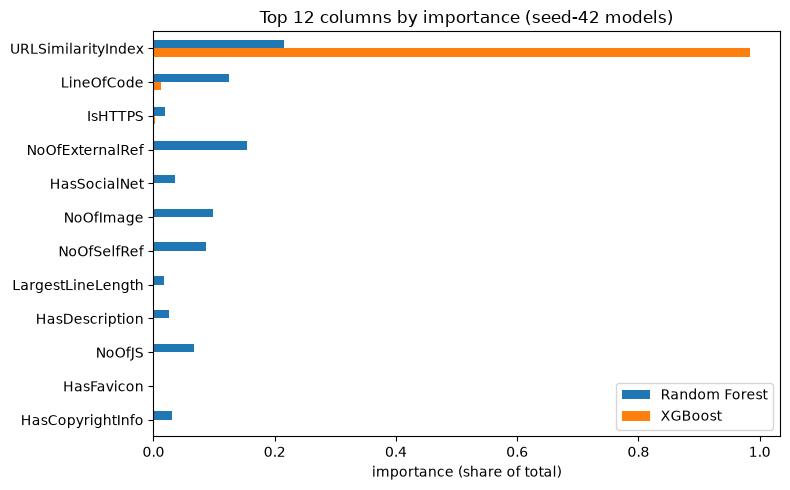

In [6]:
importance = pd.DataFrame({
    "Random Forest": rf.reference.model.feature_importances_,
    "XGBoost": xgb.reference.model.feature_importances_,
}, index=X.columns)
importance.sort_values("XGBoost", ascending=False).head(12).plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title("Top 12 columns by importance (seed-42 models)")
plt.xlabel("importance (share of total)")
plt.tight_layout()
plt.show()

## What we learned

1. **We reproduced the published result:** 99.99–100% on every one of 5 splits, even with the simplest model, and while keeping each website's links in one part of the split.
2. **That's suspicious.** When even a weighted sum is nearly perfect, a few columns are probably giving the answer away. Milestone 3 (notebooks 06 and 07) investigates this.
3. **Our app can't use these columns anyway.** Several of the top ones (`URLSimilarityIndex`, page counts like `LineOfCode`) need the downloaded web page or an outside list. A user only gives us a link.

**Next, notebook 03:** the same models, but using only numbers we compute from the link itself.